# Card Activation & Loyalty Analysis

**Client question (fictional Polish retail bank):** many credit card holders rarely use their cards or stop using them.
Which customer segments are inactive or at risk, what drives it, and what should the bank do to raise card usage?

This notebook runs the whole analysis top to bottom:
1. Load the CSV into a SQL database and check data quality
2. RFM-style activity segmentation (SQL window functions)
3. Drivers of low usage and churn
4. Charts, Excel workbook and deck

All logic lives in `sql/` (the queries) and `src/` (Python helpers), so every number shown here comes from a SQL query.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import pandas as pd
from IPython.display import Image, display
import run_sql

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Step 1 — Load the data and check its quality

`run_sql.run_all()` creates a fresh SQLite database, runs `01_create_table.sql`, loads `data/raw/BankChurners.csv`
(dropping the two `Naive_Bayes_Classifier...` columns, which are another model's predictions, not customer data)
and then runs the other SQL files in order. Each named query's result is saved to `data/processed/<name>.csv`.

In [2]:
results = run_sql.run_all()
results["dq_row_count"]

Loaded 10127 rows; dropped columns: 2
Ran 02_data_quality.sql
Ran 03_segmentation.sql


Ran 04_drivers.sql


,n_customers,n_attrited,attrition_rate_pct
0,10127,1627,16.1


In [3]:
display(results["dq_duplicates"])
display(results["dq_missing_unknown"])
display(results["dq_nulls_numeric"])

,n_rows,n_distinct_clients,n_duplicates
0,10127,10127,0


,column_name,n_null,n_unknown
0,Education_Level,0,1519
1,Marital_Status,0,749
2,Income_Category,0,1112
3,Gender,0,0
4,Card_Category,0,0


,null_inactive,null_contacts,null_trans_amt,null_trans_ct,null_ct_chng,null_util
0,0,0,0,0,0,0


In [4]:
display(results["dq_ranges"].T.rename(columns={0: "value"}))
display(results["dq_open_to_buy"])

,value
min_age,26.000
max_age,73.000
min_inactive,0.000
max_inactive,6.000
min_contacts,0.000
max_contacts,6.000
min_limit,1438.300
max_limit,34516.000
min_spend,510.000
max_spend,18484.000


,n_inconsistent
0,0


**Data notes:** no duplicate customers, no NULLs, no negative amounts, utilization within 0–1, and
`Avg_Open_To_Buy` always equals `Credit_Limit - Total_Revolving_Bal`. Three text columns have an `Unknown`
category (Education, Marital status, Income). We keep `Unknown` as its own category instead of deleting
those customers, because none of them is used in the segmentation rules.

In [5]:
results["dq_inactive_distribution"]

,Months_Inactive_12_mon,n_customers,pct_of_base
0,0,29,0.3
1,1,2233,22.0
2,2,3282,32.4
3,3,3846,38.0
4,4,435,4.3
5,5,178,1.8
6,6,124,1.2


Months inactive takes only the values 0–6 and 38% of customers sit at exactly 3. That's why the
recency score uses fixed bands instead of `NTILE(4)` (see the next step).

## Step 2 — RFM-style segmentation

| Dimension | Column | Score 1–4 |
|---|---|---|
| R (recency proxy) | `Months_Inactive_12_mon` | fixed bands: 4 = 0–1 months, 3 = 2, 2 = 3, 1 = 4+ |
| F (frequency) | `Total_Trans_Ct` | `NTILE(4)` quartiles, 4 = most transactions |
| M (monetary) | `Total_Trans_Amt` | `NTILE(4)` quartiles, 4 = most spend |

Segment rules, checked top to bottom (first match wins):
1. **Champions** — F = 4 and M = 4 and R ≥ 3
2. **At risk** — R ≤ 2 (3+ inactive months) and Q4 transactions down 40%+ vs Q1 (`Total_Ct_Chng_Q4_Q1 < 0.6`)
3. **Dormant** — F = 1 and M = 1
4. **Low-activity** — F + M ≤ 4
5. **Steady users** — everyone else

In [6]:
results["score_boundaries"]

,dimension,score,min_value,max_value,n_customers
0,F (transactions),1,10.0,45.0,2532
1,F (transactions),2,45.0,67.0,2532
2,F (transactions),3,67.0,81.0,2532
3,F (transactions),4,81.0,139.0,2531
4,M (spend),1,510.0,2155.0,2532
5,M (spend),2,2156.0,3899.0,2532
6,M (spend),3,3900.0,4741.0,2532
7,M (spend),4,4741.0,18484.0,2531
8,R (recency bands),1,4.0,6.0,737
9,R (recency bands),2,3.0,3.0,3846


In [7]:
results["segment_summary"]

,segment,n_customers,pct_of_base,avg_spend,avg_transactions,avg_months_inactive,avg_ct_change_q4_q1,avg_utilization,n_attrited,pct_of_all_attrited,attrition_rate_pct
0,1. Champions,989,9.8,10183.0,98.5,1.57,0.72,0.238,10,0.6,1.0
1,2. At risk,1367,13.5,2983.0,50.9,3.24,0.46,0.229,613,37.7,44.8
2,3. Dormant,1555,15.4,1504.0,32.8,2.06,0.76,0.281,274,16.8,17.6
3,4. Low-activity,1815,17.9,2651.0,53.1,2.21,0.73,0.262,480,29.5,26.4
4,5. Steady users,4401,43.5,5294.0,77.8,2.39,0.76,0.301,250,15.4,5.7


## Step 3 — Drivers of low usage and churn

In [8]:
display(results["attr_by_inactive"])
display(results["attr_by_contacts"])

,months_inactive,n_customers,n_attrited,attrition_rate_pct
0,0,29,15,51.7
1,1,2233,100,4.5
2,2,3282,505,15.4
3,3,3846,826,21.5
4,4,435,130,29.9
5,5,178,32,18.0
6,6,124,19,15.3


,contacts_12m,n_customers,n_attrited,attrition_rate_pct
0,0,399,7,1.8
1,1,1499,108,7.2
2,2,3227,403,12.5
3,3,3380,681,20.1
4,4,1392,315,22.6
5,5,176,59,33.5
6,6,54,54,100.0


In [9]:
display(results["attr_by_card"])
display(results["attr_by_income"])
display(results["attr_by_age"])

,card_category,n_customers,attrition_rate_pct,avg_spend,avg_transactions
0,Blue,9436,16.1,4225.0,64.0
1,Silver,555,14.8,6590.0,74.7
2,Gold,116,18.1,7686.0,81.5
3,Platinum,20,25.0,9000.0,87.0


,income_category,n_customers,attrition_rate_pct
0,$120K +,727,17.3
1,Less than $40K,3561,17.2
2,Unknown,1112,16.8
3,$80K - $120K,1535,15.8
4,$40K - $60K,1790,15.1
5,$60K - $80K,1402,13.5


,age_band,n_customers,attrition_rate_pct
0,1. <35,735,13.7
1,2. 35-44,3440,15.9
2,3. 45-54,4342,16.5
3,4. 55+,1610,16.3


Card tier, income and age show only small differences in attrition (roughly 13–18% for groups of a
meaningful size), so they are **not** among the strongest findings.

In [10]:
display(results["activity_change_by_status"])
display(results["attr_by_ct_change_band"])

,status,n_customers,avg_ct_change_q4_q1,median_ct_change_q4_q1,avg_amt_change_q4_q1,pct_trans_down_40pct_plus,avg_transactions,avg_spend,avg_utilization
0,Attrited Customer,1627,0.55,0.53,0.69,61.8,44.9,3095.0,0.162
1,Existing Customer,8500,0.74,0.72,0.77,21.2,68.7,4655.0,0.296


,ct_change_band,n_customers,attrition_rate_pct
0,1. down >60%,650,60.0
1,2. down 40-60%,2158,28.5
2,3. down 20-40%,4390,9.2
3,4. down 0-20%,2095,7.6
4,5. flat or up,834,7.1


In [11]:
display(results["utilization_by_segment"])
display(results["early_warning_combo"])

,segment,status,n_customers,avg_utilization,pct_zero_revolving_balance
0,1. Champions,Attrited Customer,10,0.006,80.0
1,1. Champions,Existing Customer,979,0.240,15.0
2,2. At risk,Attrited Customer,613,0.154,54.2
3,2. At risk,Existing Customer,754,0.289,16.0
4,3. Dormant,Attrited Customer,274,0.159,58.8
5,3. Dormant,Existing Customer,1281,0.307,13.0
6,4. Low-activity,Attrited Customer,480,0.217,53.8
7,4. Low-activity,Existing Customer,1335,0.278,17.8
8,5. Steady users,Attrited Customer,250,0.088,53.6
9,5. Steady users,Existing Customer,4151,0.314,21.8


,group_name,n_customers,pct_of_base,n_attrited,pct_of_all_attrited,attrition_rate_pct
0,Flagged: 3+ inactive months and 3+ contacts,2317,22.9,686,42.2,29.6
1,Not flagged,7810,77.1,941,57.8,12.0


### The 3 strongest findings
1. **Falling activity** — the clearest split between churned and retained customers (Q4-vs-Q1 transaction change).
2. **Inactivity** — attrition rises steeply from 1 to 4 inactive months.
3. **Bank contacts** — attrition rises with every contact.

These are correlations in a snapshot, not proven causes.

## Step 4 — Charts, Excel workbook, deck

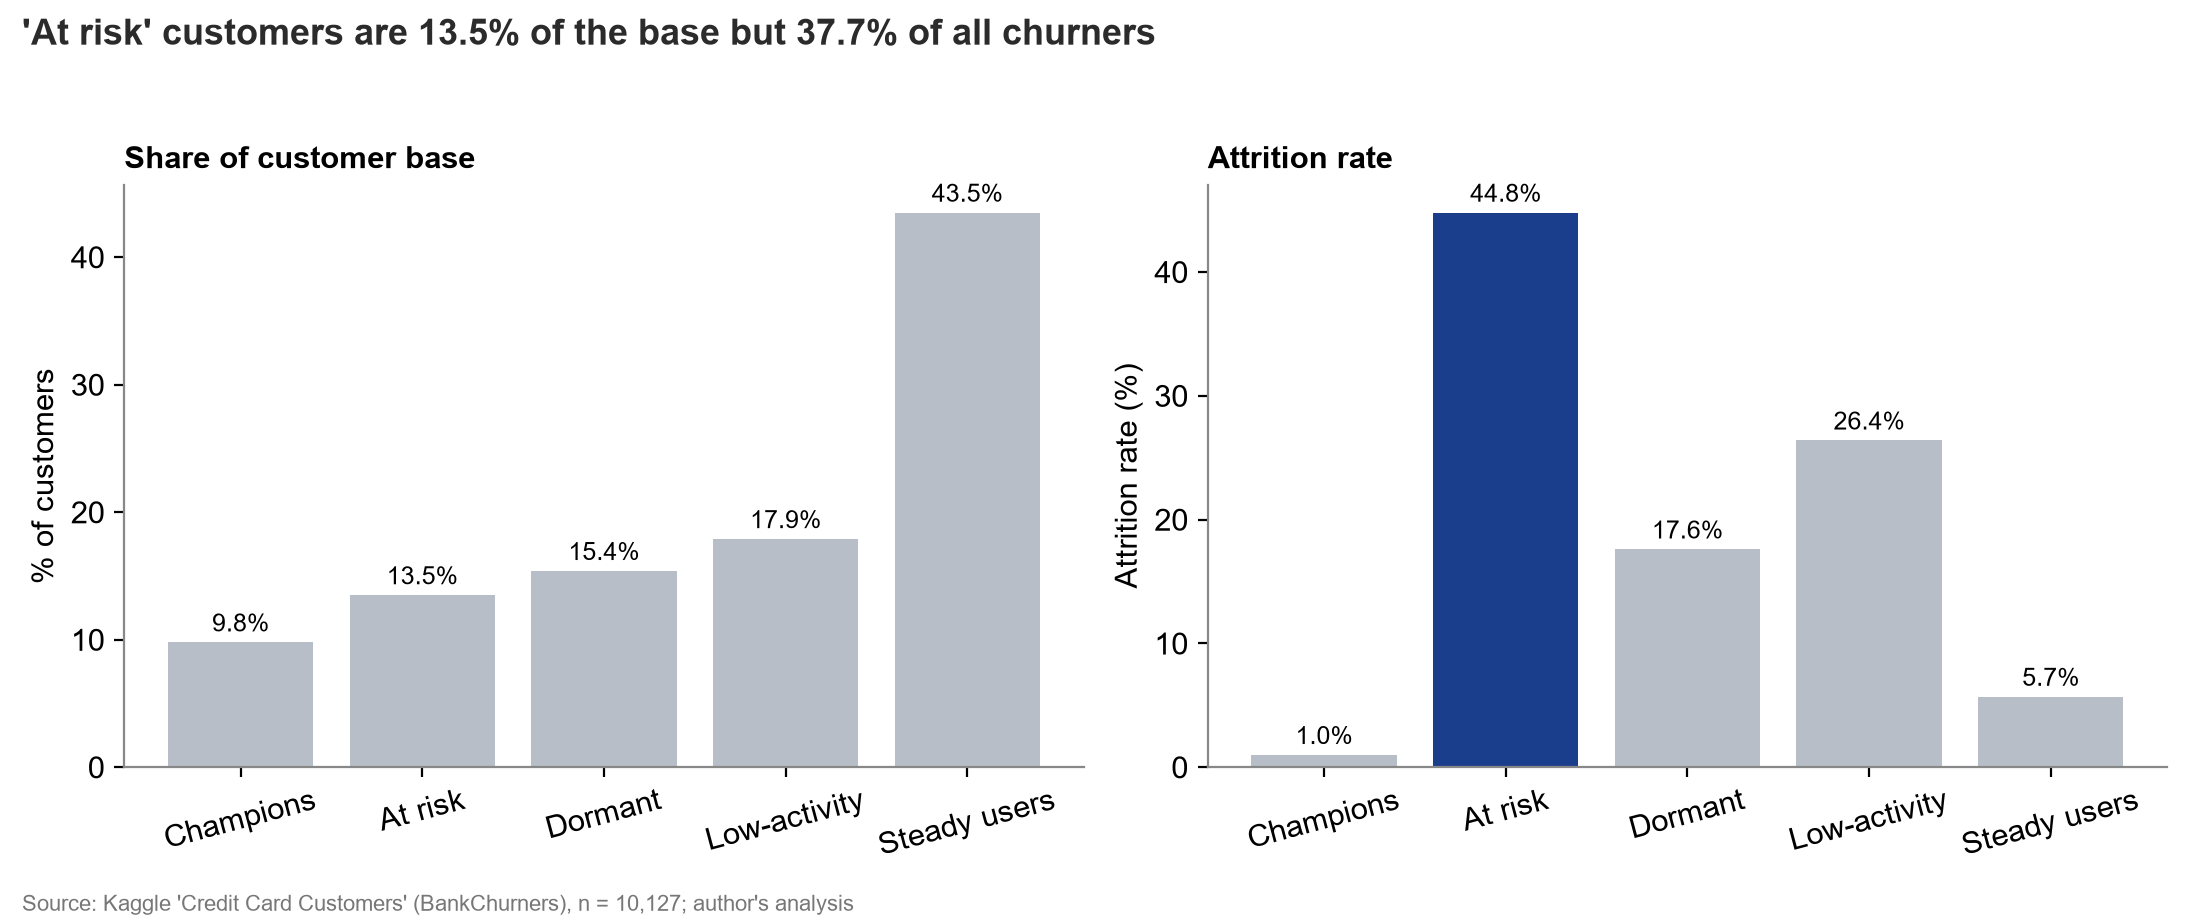

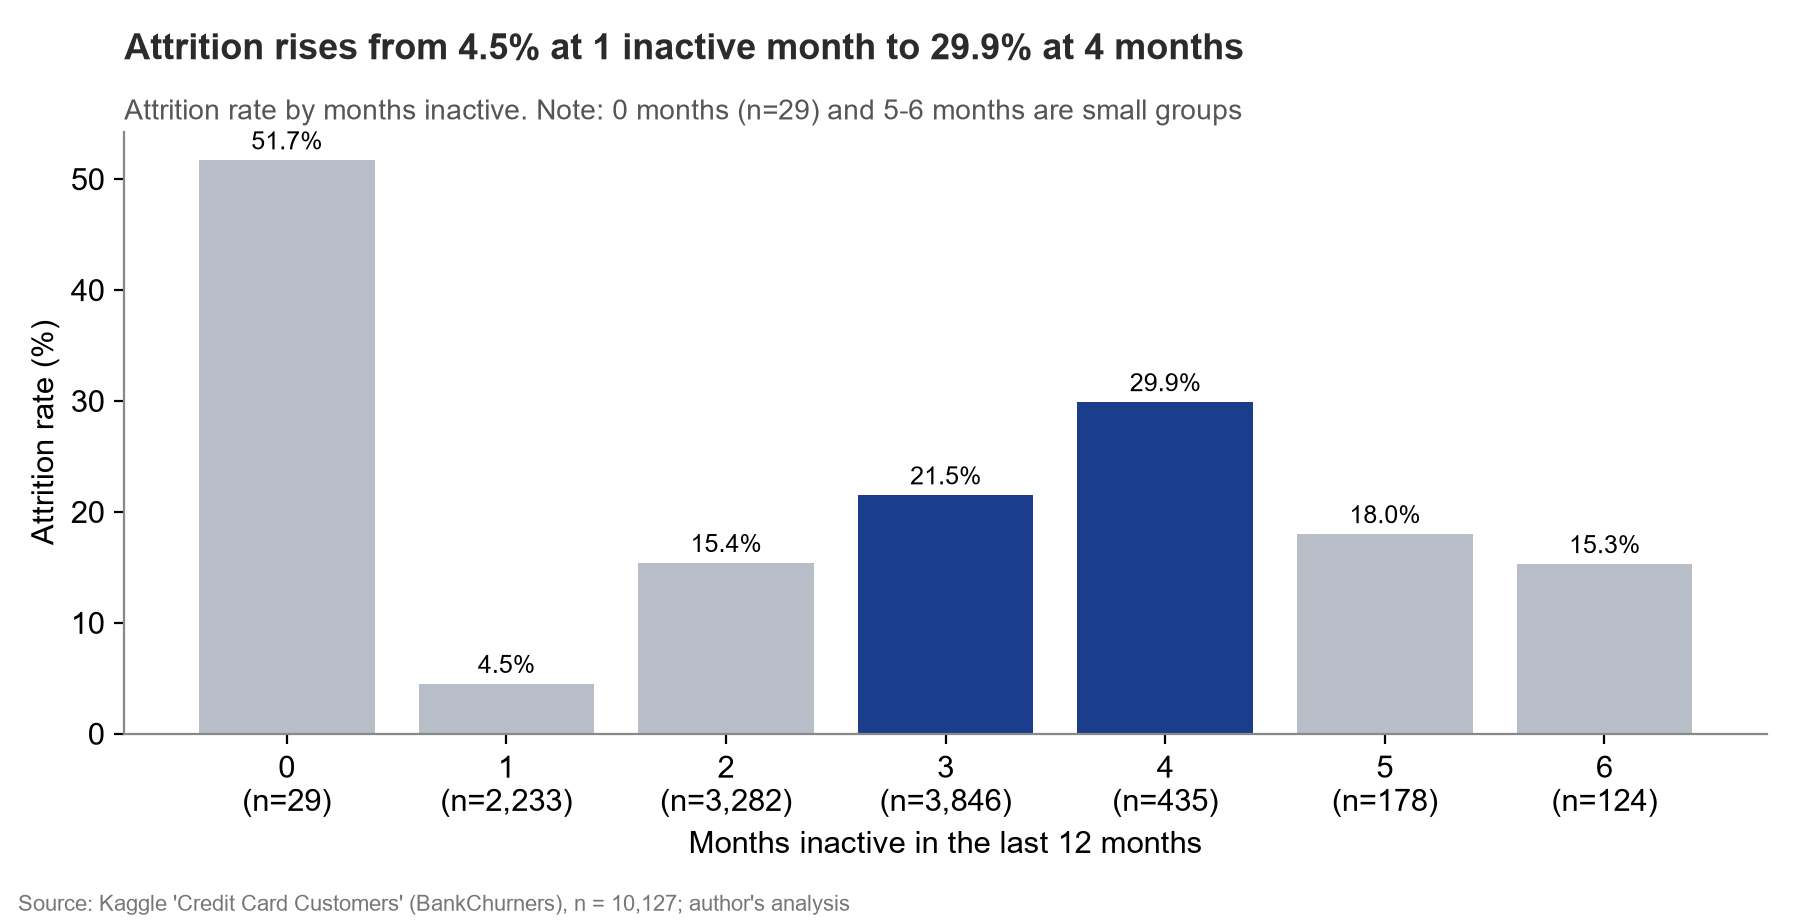

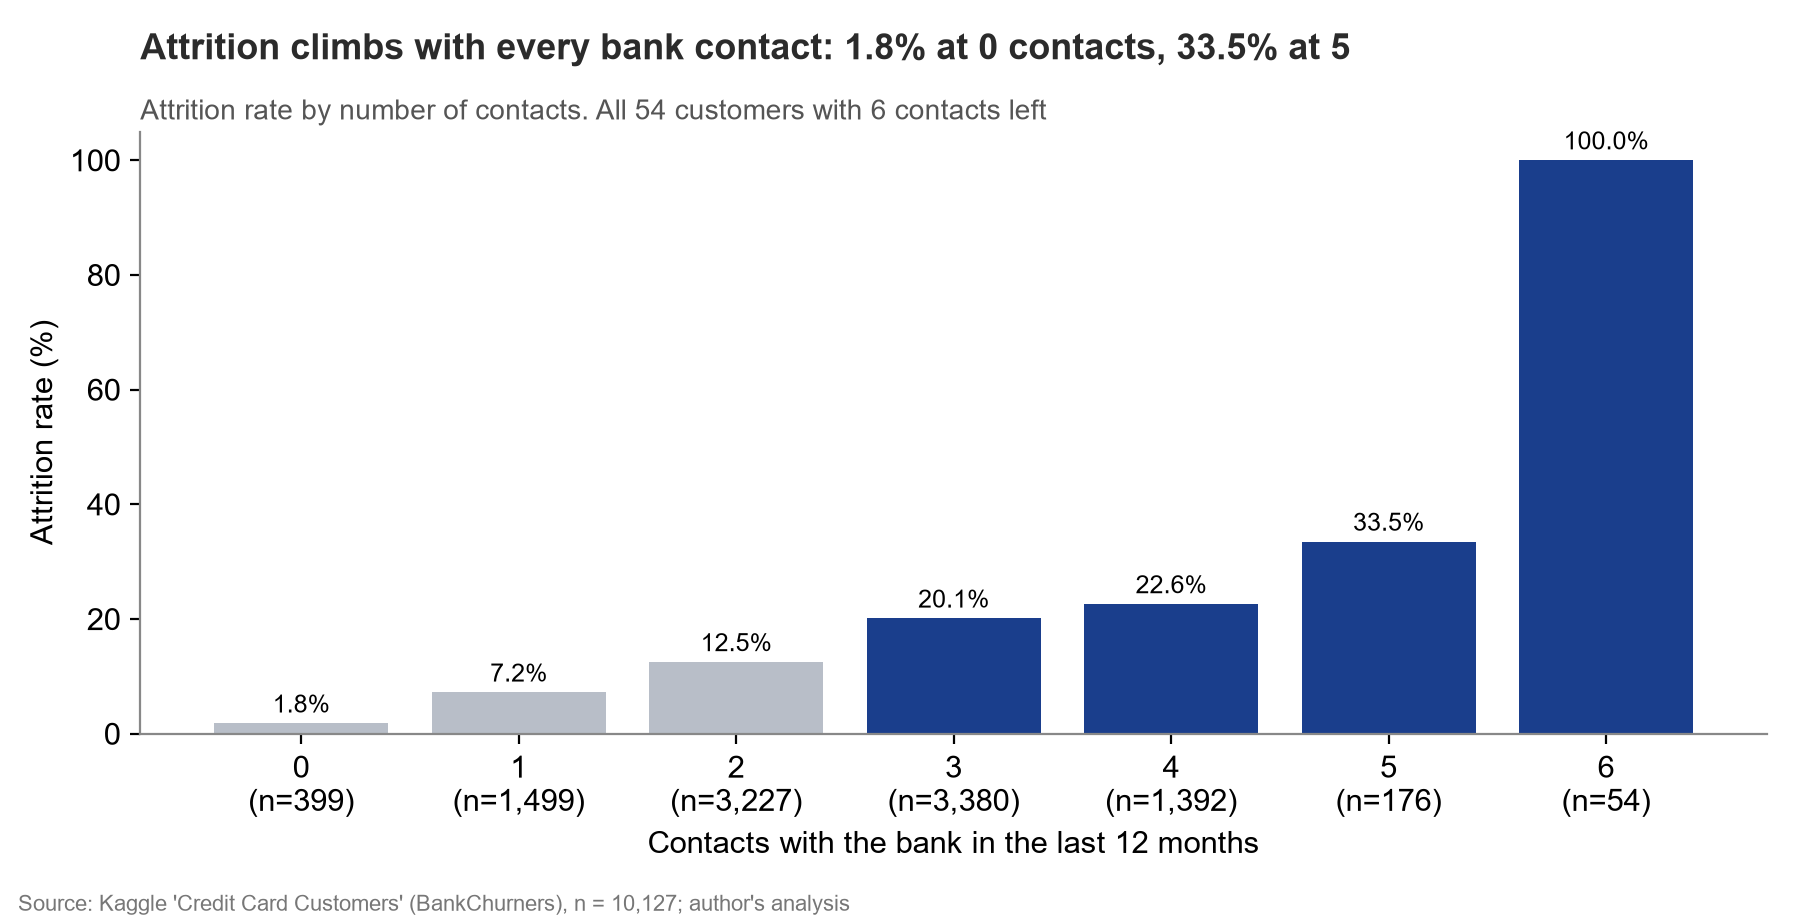

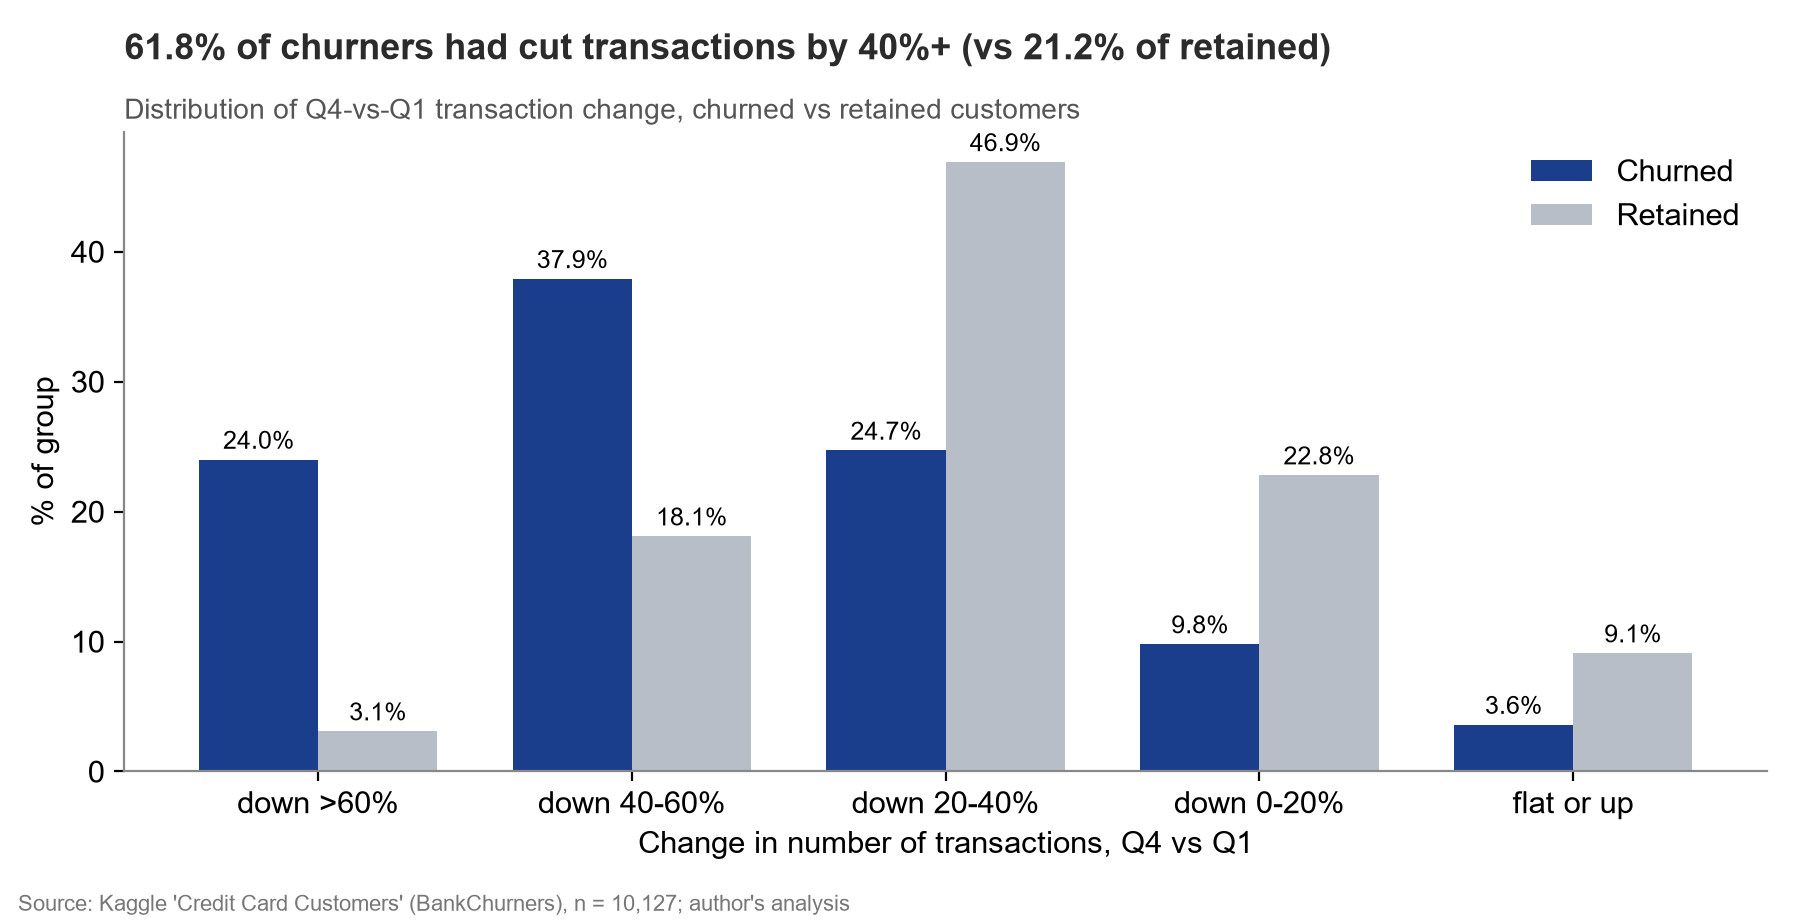

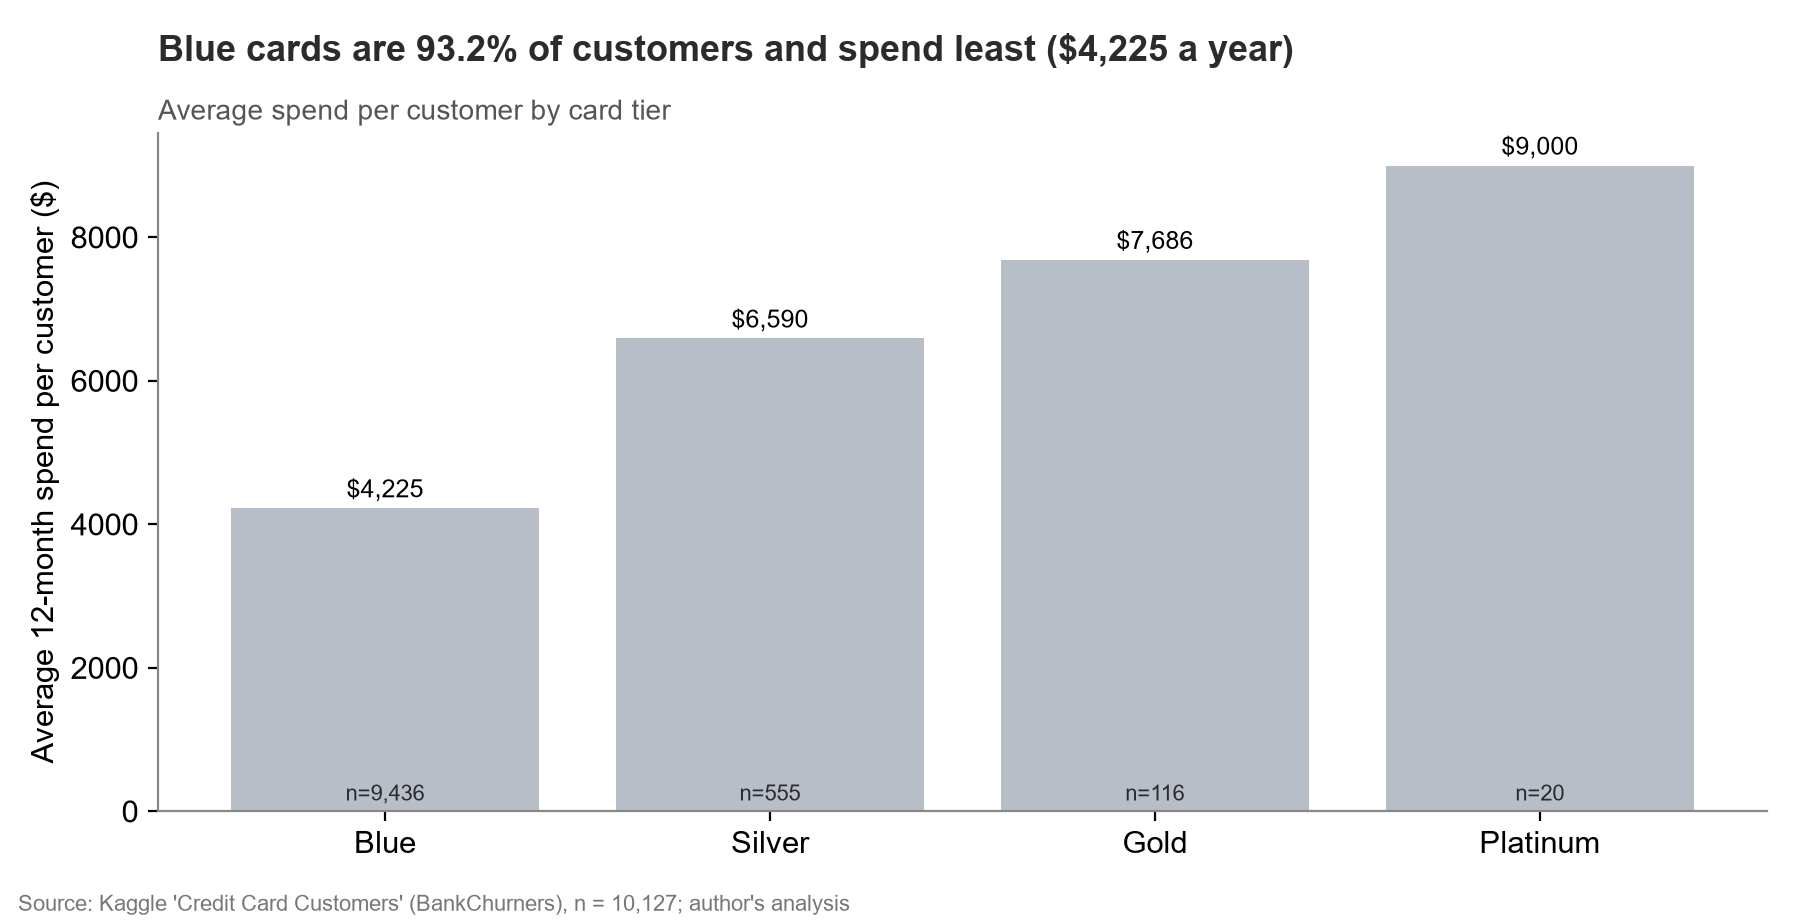

In [12]:
import charts, excel, deck
charts.make_all()
excel.build()
deck.build()
for f in sorted((Path.cwd().parent / "outputs" / "charts").glob("*.png")):
    display(Image(filename=str(f), width=800))

The deck is saved to `outputs/card_activation_deck.pptx`. On Windows with PowerPoint installed,
`powershell -ExecutionPolicy Bypass -File src/export_pdf.ps1` exports it to PDF.